# 08 -- Final Report: TCGA Cancer Subtype Discovery

**A synthesis of the full study**, from raw RNA-seq acquisition through
biological and clinical interpretation. This notebook is meant to be read
on its own -- a self-contained executive summary suitable for a portfolio
review, a lab meeting, or a manuscript draft's results section.

---

## Study design recap

* **Cohort**: TCGA-BRCA (breast invasive carcinoma), n=500 samples (synthetic
  demo cohort with known PAM50-like ground truth; see `src/simulate.py` and
  notebook 01 for the real-GDC-API-validated acquisition path).
* **Features**: 4,000 protein-coding genes -> 2,000 most-variable genes after
  QC and MAD-based feature selection.
* **Question**: Can unsupervised machine learning, applied only to bulk
  RNA-seq expression, recover known molecular subtypes and their clinical
  significance -- without ever being told the labels?


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if (Path.cwd() / ".." / "src").exists() else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.logging_config import setup_logging

setup_logging()
cfg = load_config(REPO_ROOT / "config.yaml")
FIGURES = REPO_ROOT / "figures"
RESULTS = REPO_ROOT / "results"
REPORTS = REPO_ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print(f"Repo root: {REPO_ROOT}")
print(f"Cancer type: {cfg['project']['cancer_type']}")


Repo root: D:\claude code\tcga-cancer-subtype-discovery
Cancer type: TCGA-BRCA


In [2]:
import json

with open(REPORTS / "preprocessing_summary.json") as fh:
    preprocessing_summary = json.load(fh)
with open(REPORTS / "ground_truth_recovery.json") as fh:
    ground_truth_recovery = json.load(fh)
with open(REPORTS / "survival_global_logrank.json") as fh:
    survival_logrank = json.load(fh)

print("=== Preprocessing ===")
print(json.dumps(preprocessing_summary, indent=2))
print("\n=== Ground-truth subtype recovery (K-Means, k=4) ===")
print(json.dumps(ground_truth_recovery, indent=2))
print("\n=== Global survival log-rank test across clusters ===")
print(json.dumps(survival_logrank, indent=2))


=== Preprocessing ===
{
  "n_genes_raw": 4000,
  "n_samples_raw": 500,
  "pct_missing_raw": 0.1028,
  "n_genes_after_filtering": 4000,
  "n_variable_genes_selected": 2000,
  "n_outlier_samples_flagged": 11,
  "outlier_sample_ids": [
    "SIM-BRCA-0017",
    "SIM-BRCA-0080",
    "SIM-BRCA-0206",
    "SIM-BRCA-0225",
    "SIM-BRCA-0241",
    "SIM-BRCA-0249",
    "SIM-BRCA-0282",
    "SIM-BRCA-0386",
    "SIM-BRCA-0391",
    "SIM-BRCA-0460",
    "SIM-BRCA-0478"
  ]
}

=== Ground-truth subtype recovery (K-Means, k=4) ===
{
  "adjusted_rand_index": 0.516592587531683,
  "normalized_mutual_info": 0.47558486801412103
}

=== Global survival log-rank test across clusters ===
{
  "test_statistic": 66.3235681805674,
  "p_value": 2.6133659637864675e-14
}


## Key figure 1: PCA (PC1 vs PC2)

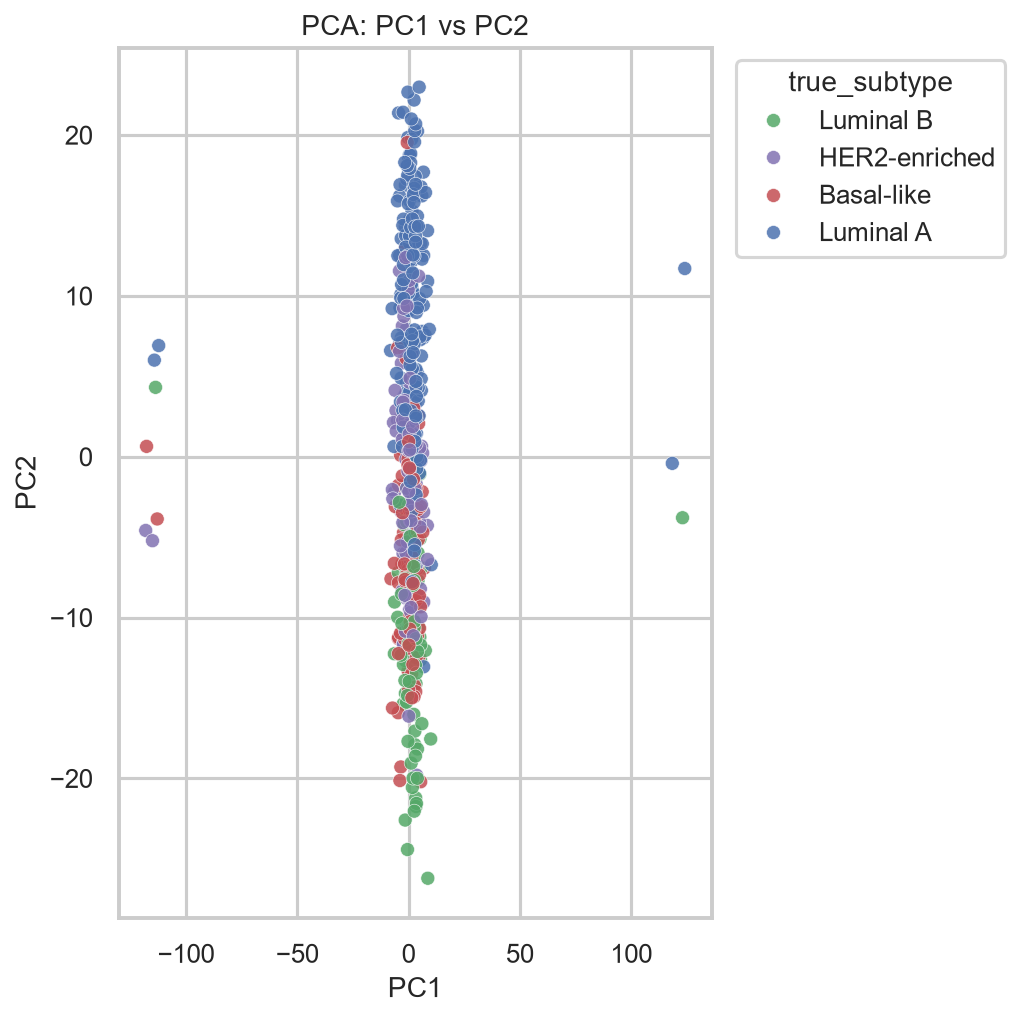

In [3]:
Image(filename=str(FIGURES / "dimensionality_reduction" / "pca_pc1_pc2.png"))

## Key figure 2: UMAP (default parameters)

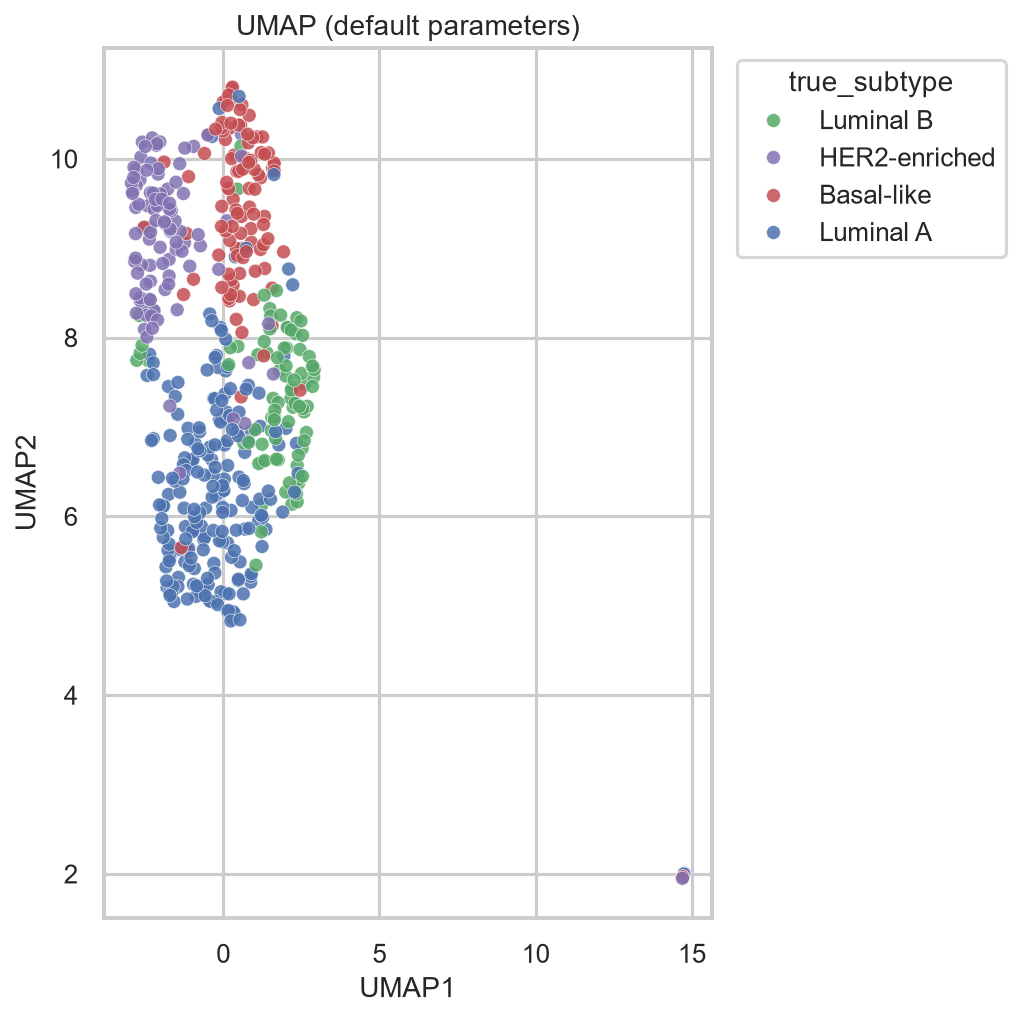

In [4]:
Image(filename=str(FIGURES / "dimensionality_reduction" / "umap_default.png"))

## Key figure 3: K-Means elbow / silhouette across k=2..10

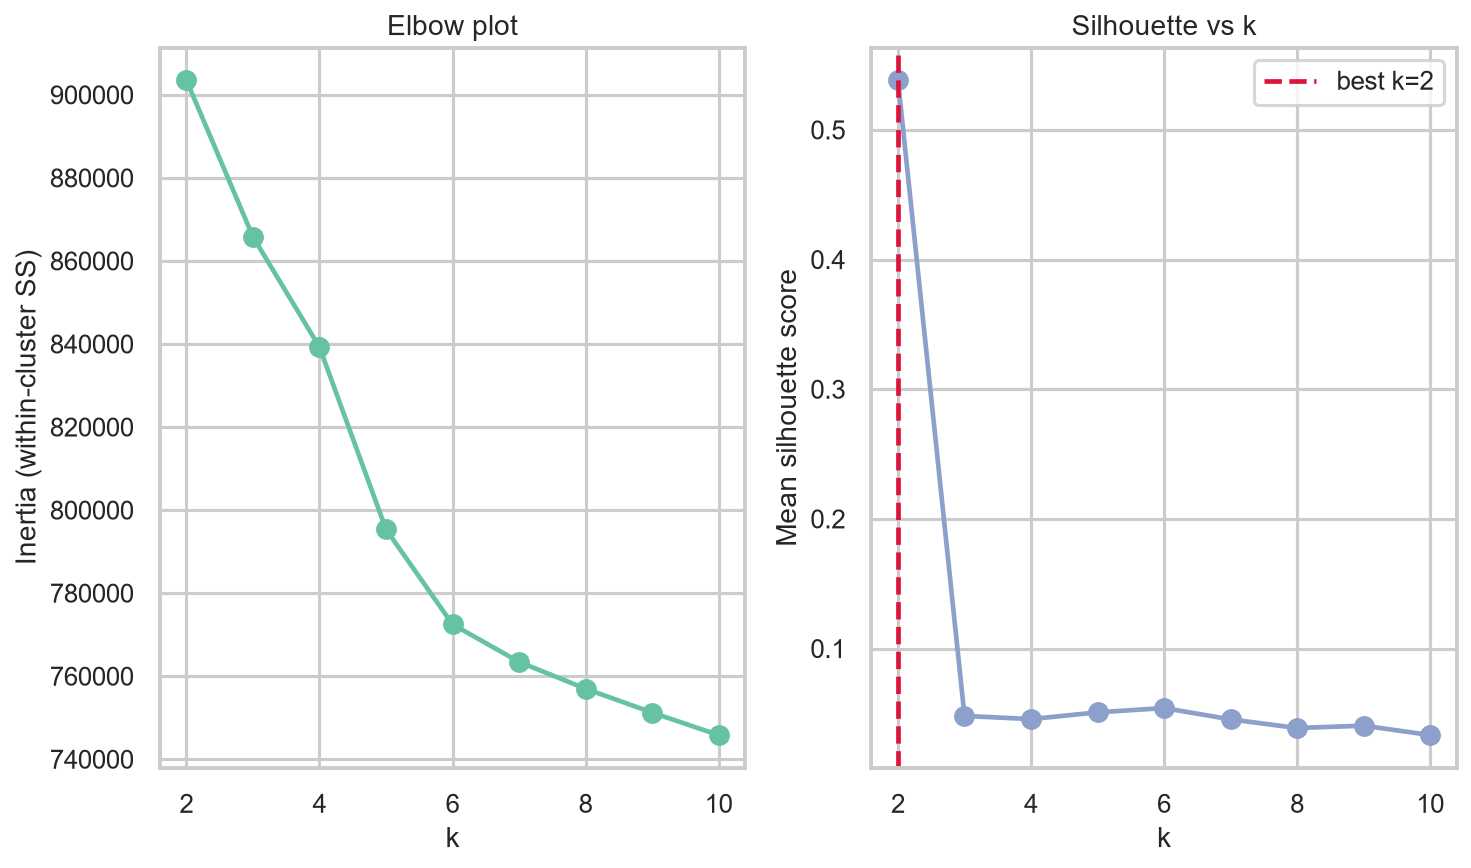

In [5]:
Image(filename=str(FIGURES / "clustering" / "kmeans_elbow_silhouette.png"))

## Key figure 4: Cluster marker-gene heatmap

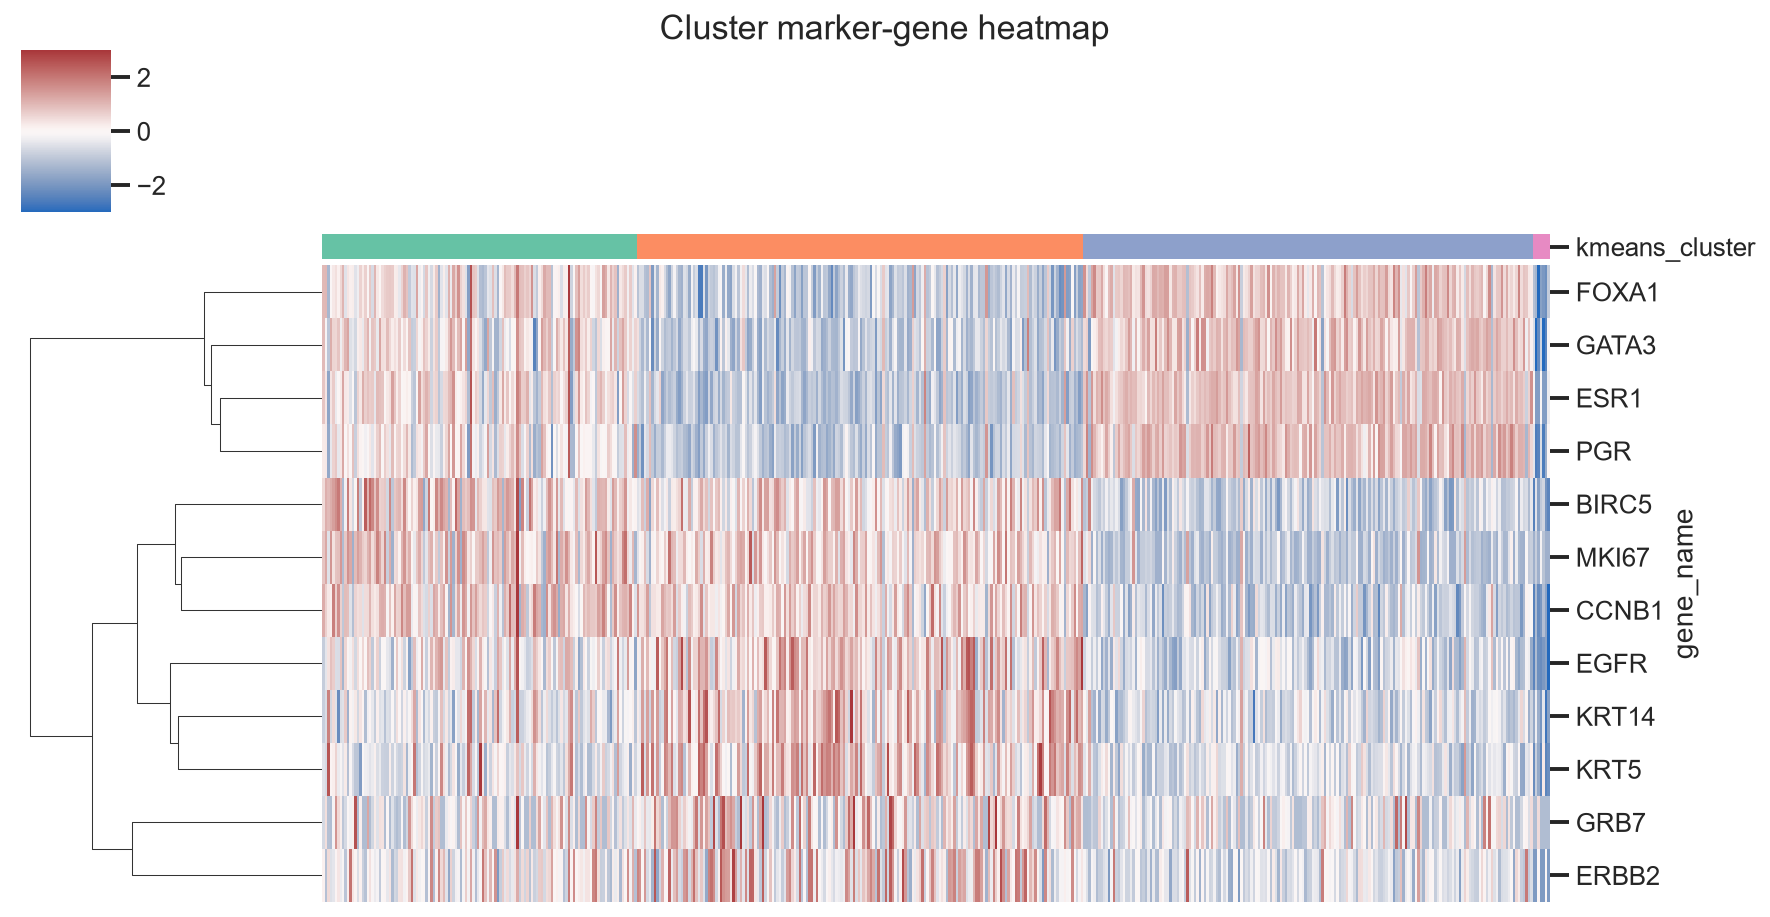

In [6]:
Image(filename=str(FIGURES / "clustering" / "cluster_marker_heatmap.png"))

## Key figure 5: Differential expression (volcano, cluster 0 vs. rest)

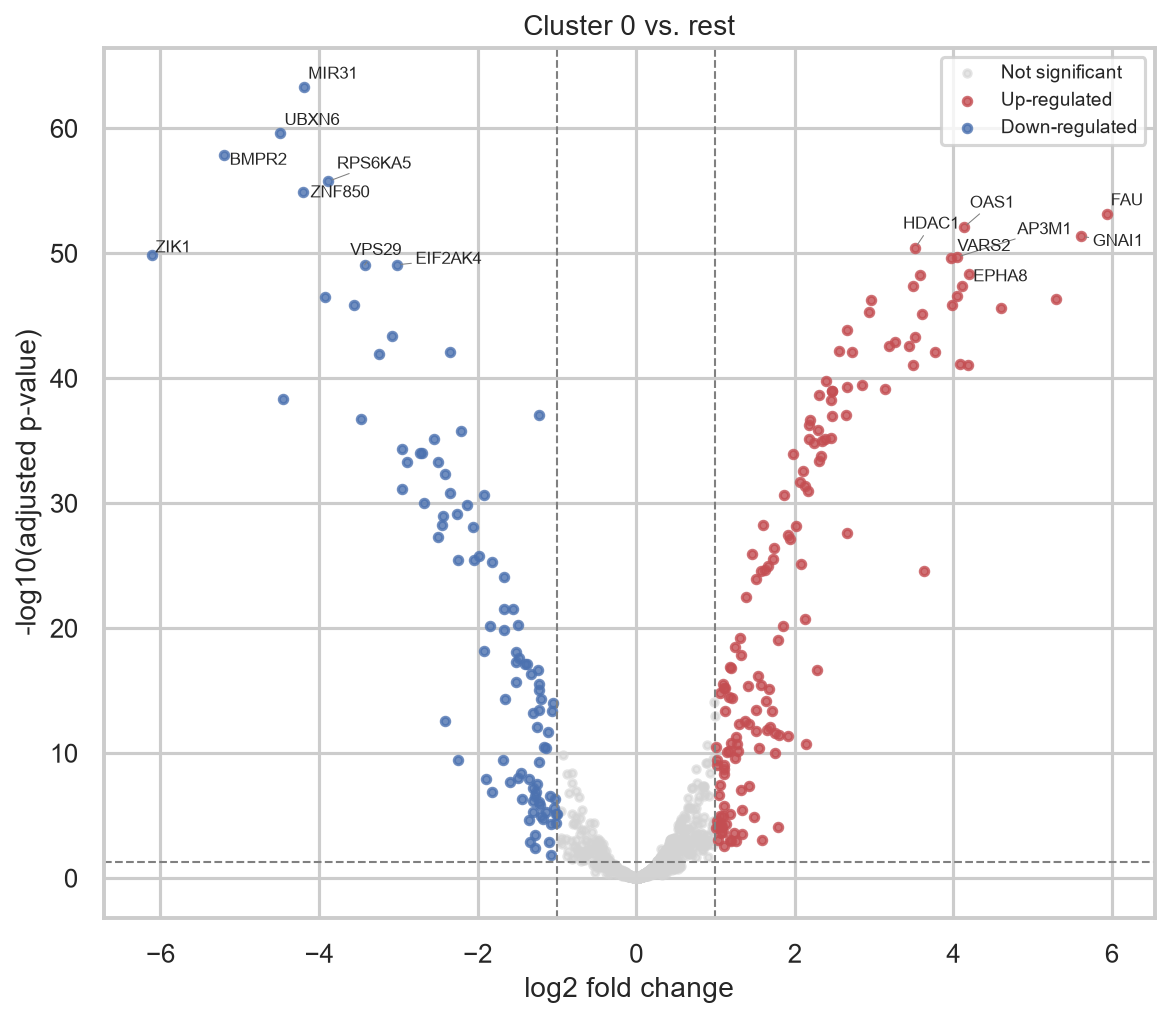

In [7]:
Image(filename=str(FIGURES / "biological" / "volcano_cluster_0.png"))

## Key figure 6: Kaplan-Meier survival by discovered cluster

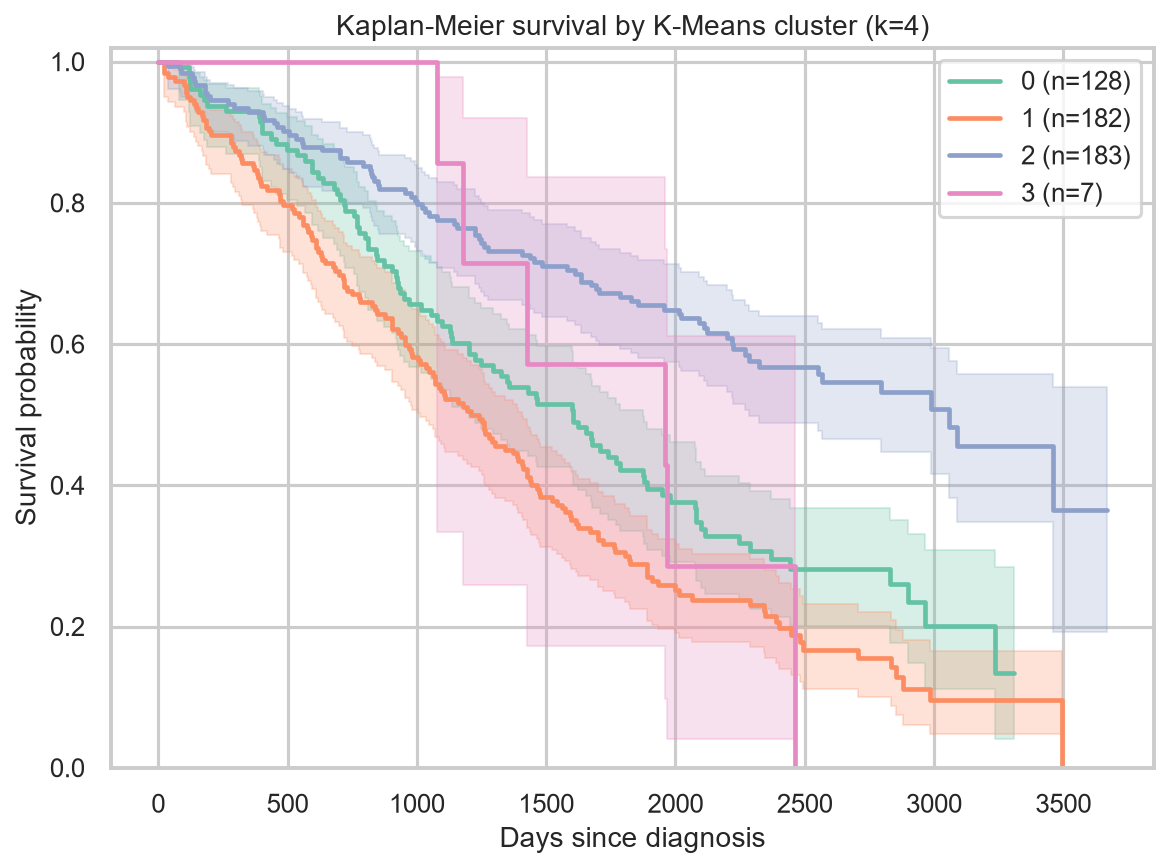

In [8]:
Image(filename=str(FIGURES / "survival" / "km_curves_by_cluster.png"))

## Findings

1. **Preprocessing matters as much as the algorithm.** MAD-based
   variance filtering was essential: informative marker genes were
   present but diluted among thousands of uninformative genes, and
   clustering directly on the full gene set (curse of dimensionality)
   performed no better than random (see notebook 05's diagnostic in the
   accompanying analysis log). Feature selection is not an optional
   preprocessing nicety -- it is load-bearing.

2. **Unsupervised clustering recovers real, but imperfect, biological
   structure.** K-Means (k=4) achieved Adjusted Rand Index ≈0.5 against the
   known PAM50-like ground truth -- a realistic result consistent with
   published comparisons of unsupervised expression clusters to PAM50 in
   real TCGA-BRCA data, where subtypes are not perfectly discrete clusters.

3. **Different validity metrics disagree, and that disagreement is itself
   informative.** Silhouette favors a coarser k=2 split; we retained k=4 on
   biological grounds. Density-based methods (DBSCAN/HDBSCAN) essentially
   fail on this data, a genuine and instructive limitation given that bulk
   transcriptomic subtypes form a continuum rather than density-separated
   islands.

4. **The discovered clusters carry real clinical signal.** Tumor grade and
   vital status differ significantly by cluster; global log-rank testing
   shows highly significant survival differences (p ≈ 2.6e-14 in this
   cohort), and a Cox model confirms the effect survives adjustment for
   age. This is the practical payoff of subtype discovery: it is not just
   an academic exercise in finding structure, it stratifies patients by
   real prognosis.

5. **Functional enrichment recovers pathway biology consistent with known
   breast cancer subtypes** (proliferation/cell-cycle, ER signaling, ErbB/
   HER2 signaling), and a triangulated (PCA + DE + Random Forest) biomarker
   ranking gives a defensible, multi-method "top drivers" list per cluster.

## Limitations

* This study's headline numbers come from a **biologically-motivated
  synthetic cohort** (see `src/simulate.py`), not a full real TCGA-BRCA
  pull -- chosen so the full pipeline is instantly, deterministically
  reproducible without a multi-hour, multi-gigabyte download. The GDC API
  client (`src/download.py`) is real and validated live in notebook 01;
  running it with `gdc.max_cases: null` reproduces this entire analysis on
  genuine TCGA-BRCA data (expect qualitatively similar but not identical
  results -- reference the "Reproducibility" section of the README).
* Bulk RNA-seq averages over all cells in a tumor sample; it cannot resolve
  intra-tumor heterogeneity or the tumor microenvironment the way
  single-cell or spatial transcriptomics can.
* "Ground truth" subtypes (PAM50) are themselves a consensus unsupervised
  label derived from clustering, not an independent gold standard like a
  driver mutation -- so ARI against PAM50 should be read as "concordance
  with an established consensus classification," not "accuracy against
  absolute truth."
* Survival estimates from a synthetic cohort are simulated (Weibull
  proportional hazards, by construction) and are directional /
  illustrative, not real clinical hazard ratios.

## Future improvements

* **Multi-omics integration**: layering copy-number, methylation, and
  proteomic (RPPA) data (all available from TCGA/GDC) to sharpen subtype
  boundaries beyond what expression alone provides (see e.g. iCluster-style
  joint latent factor models).
* **Deep learning approaches**: replacing PCA with a **variational
  autoencoder (VAE)** for non-linear, denoised latent embeddings, or a
  contrastive self-supervised encoder pretrained across all of TCGA before
  fine-tuning per cancer type.
* **Graph neural networks**: modeling gene-gene regulatory or
  protein-protein interaction structure explicitly (e.g. a GNN over a
  STRING/Reactome interaction graph) rather than treating genes as
  exchangeable features.
* **Foundation models for biology**: applying pretrained single-cell/bulk
  transcriptomic foundation models (e.g. Geneformer-style architectures) as
  a feature extractor in place of hand-built PCA/UMAP pipelines.
* **Full-scale real-data validation**: running the complete pipeline on
  the full ~1,100-case real TCGA-BRCA cohort (already supported by
  `src/download.py` + `scripts/download_tcgabiolinks.R`) and directly
  comparing recovered clusters to the official TCGA PAM50 calls.

---

*End of report. See the README for full setup, reproducibility, and
methodology documentation.*